# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [16]:
df = pd.read_csv('/content/listings.csv.gz')
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1534226092176355661,https://www.airbnb.com/rooms/1534226092176355661,20260627230126,2026-06-29,city scrape,Private Suite Oceanfront La Jolla,Private suite in Ocean front Estate in La Jolla,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,14064859,...,NaN,NaN,NaN,NaN,NaN,9,6,3,0,NaN
1,1151093362948878244,https://www.airbnb.com/rooms/1151093362948878244,20260627230126,2026-06-29,city scrape,Magical view,Luxury high rise building fully remodeled with...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,365015269,...,NaN,NaN,NaN,STR-08000L,NaN,1,1,0,0,NaN
2,46566873,https://www.airbnb.com/rooms/46566873,20260627230126,2026-06-28,city scrape,Highland on 60th Large 3BR 4 Beds/2 BA Near SDSU,Centrally located single-family home with a la...,NaN,https://a0.muscache.com/pictures/5b341abe-0010...,21897271,...,4.98,4.91,4.91,"STR-01411L, 644117",NaN,1,1,0,0,3.40
3,683340460312082362,https://www.airbnb.com/rooms/683340460312082362,20260627230126,2026-07-02,previous scrape,"Beautiful, Private Bed & Bath in Central Location",Keep it simple at this peaceful and centrally-...,NaN,https://a0.muscache.com/pictures/airflow/Hosti...,21788590,...,5.00,4.95,5.00,"STR-06725L, 644561",NaN,2,1,1,0,0.45
4,50119879,https://www.airbnb.com/rooms/50119879,20260627230126,2026-06-29,city scrape,Wooden Craftsman Home w/ Private Backyard & Ga...,Make this entire space your new home away from...,NaN,https://a0.muscache.com/pictures/8b957cbc-f489...,117810403,...,4.93,4.98,4.79,"STR-06662L, 648042",NaN,1,1,0,0,0.95


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

                              missing_count  missing_percent
neighborhood_overview                 13225       100.000000
host_since                            13225       100.000000
host_total_listings_count             13225       100.000000
neighbourhood                         13225       100.000000
host_verifications                    13225       100.000000
host_response_rate                    13225       100.000000
host_acceptance_rate                  13225       100.000000
host_thumbnail_url                    13225       100.000000
host_response_time                    13225       100.000000
host_neighbourhood                    13225       100.000000
instant_bookable                      13225       100.000000
calendar_updated                      13225       100.000000
neighbourhood_group_cleansed          13225       100.000000
host_about                             4842        36.612476
license                                2986        22.578450
host_location           

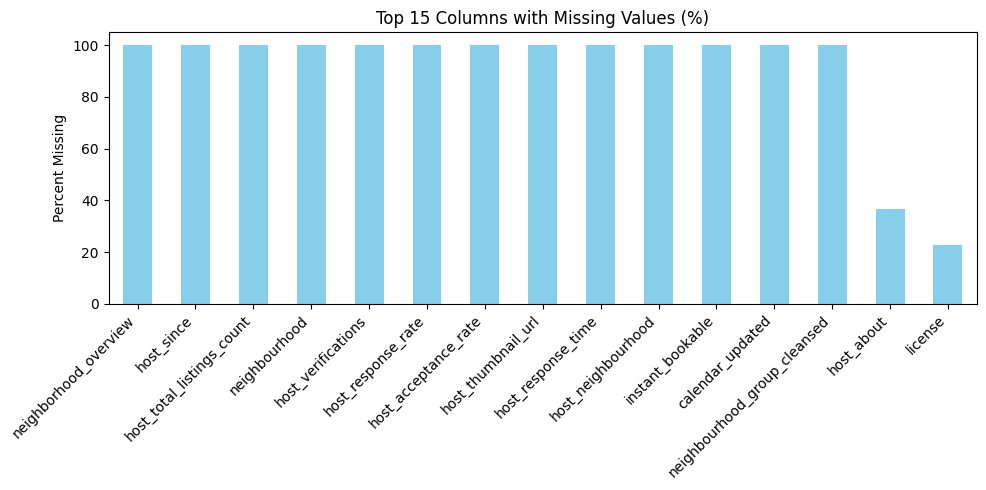

In [17]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'missing_count': df.isnull().sum(), 'missing_percent': missing_percent})
print(missing_df[missing_df['missing_count'] > 0].sort_values(by='missing_percent', ascending=False))

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
missing_percent[missing_percent > 0].sort_values(ascending=False).head(15).plot(kind='bar', color='skyblue')
plt.title('Top 15 Columns with Missing Values (%)')
plt.ylabel('Percent Missing')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. Looking at the chart, the top columns that are near the 100% missing are calendar_updated, neighbourhood_group_cleared, and host_response_time.

2. I believe the missing host response metrics make it difficult to evaluate to host performance or award superhost status. There is also missing license numbers which makes it hard for regulatory and legal compliance teams to ensure listings follow local city laws.

3. The safest one to ignore would be calendar_updated because it is completely empty. neighbourhood_group_cleared can also be dropped if the city doesn't us sub regions.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [18]:
cols_to_drop = ['calendar_updated', 'listing_url', 'scrape_id', 'last_scraped', 'picture_url', 'host_url']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

print("Remaining columns:", df.shape[1])
df.head()

Remaining columns: 84


,id,source,name,description,neighborhood_overview,host_id,host_profile_id,host_profile_url,host_name,host_since,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1534226092176355661,city scrape,Private Suite Oceanfront La Jolla,Private suite in Ocean front Estate in La Jolla,NaN,14064859,1.462589e+18,https://www.airbnb.com/users/profile/146258885...,La Jolla Ranch Host,NaN,...,NaN,NaN,NaN,NaN,NaN,9,6,3,0,NaN
1,1151093362948878244,city scrape,Magical view,Luxury high rise building fully remodeled with...,NaN,365015269,1.469734e+18,https://www.airbnb.com/users/profile/146973449...,Ramsin,NaN,...,NaN,NaN,NaN,STR-08000L,NaN,1,1,0,0,NaN
2,46566873,city scrape,Highland on 60th Large 3BR 4 Beds/2 BA Near SDSU,Centrally located single-family home with a la...,NaN,21897271,1.463167e+18,https://www.airbnb.com/users/profile/146316653...,Jason,NaN,...,4.98,4.91,4.91,"STR-01411L, 644117",NaN,1,1,0,0,3.40
3,683340460312082362,previous scrape,"Beautiful, Private Bed & Bath in Central Location",Keep it simple at this peaceful and centrally-...,NaN,21788590,1.463164e+18,https://www.airbnb.com/users/profile/146316401...,Carl,NaN,...,5.00,4.95,5.00,"STR-06725L, 644561",NaN,2,1,1,0,0.45
4,50119879,city scrape,Wooden Craftsman Home w/ Private Backyard & Ga...,Make this entire space your new home away from...,NaN,117810403,1.468205e+18,https://www.airbnb.com/users/profile/146820486...,Blake,NaN,...,4.93,4.98,4.79,"STR-06662L, 648042",NaN,1,1,0,0,0.95


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. Dropped listing_url, picture_url, host_url, scrape_id, last_scraped and calendar_updated.

2.These columns contain internal web scraping metadata or media URLs that do not contribute to numerical modeling, price prediction, or occupancy analysis.

3. If we kept them it would increase memory usage and slow down computations and could cause clutters in dataset exports.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [19]:
if 'review_scores_rating' in df.columns:
    df['review_scores_rating'] = df['review_scores_rating'].fillna(df['review_scores_rating'].median())

if 'host_name' in df.columns:
    df['host_name'] = df['host_name'].fillna('Unknown Host')

print("Missing review scores left:", df['review_scores_rating'].isnull().sum())
print("Missing host names left:", df['host_name'].isnull().sum())

Missing review scores left: 0
Missing host names left: 0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned review_scores_rating and host_name

2. review_scores_rating used median imputation. The median was chosen over the mean because review scores tend to be very skewed towards 5 stars, so the median preserves the typical rating without letting very low values distort the overall average. For host_name, I used a categorical placeholder and kept the rows tagged with a default label to ensure we wouldn't lose valid listing data while clearly marking missing host identity metadata.

3. Imputing median rating scores onto listings without reviews could artificially inflate the quality perception of unrated or brand new listings, which gives a false impression of positive guest sentiment before real feedback exists.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

count    11856.000000
mean       483.802383
std        987.207536
min          5.500000
25%        175.457500
50%        322.920000
75%        589.000000
max      82340.820000
Name: price, dtype: float64


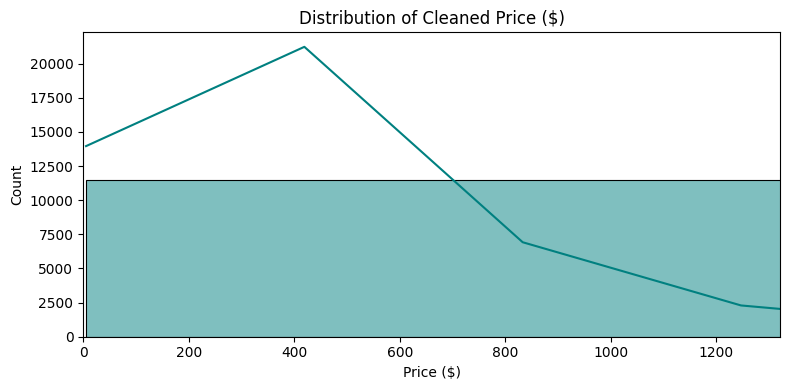

In [20]:
if 'price' in df.columns and df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

print(df['price'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df['price'].dropna(), bins=50, kde=True, color='teal')
plt.title('Distribution of Cleaned Price ($)')
plt.xlabel('Price ($)')
plt.xlim(0, df['price'].quantile(0.95)) # limit to 95th percentile to handle extreme outliers
plt.tight_layout()
plt.show()

### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. Price

2.Stripped out the currency symbols and commas using string replacements then converted the column from object/string to a numerical data type.

3. Storing price as a numeric float helped us calculate summary statistics group listings by price across neighborhoods, and use price as an outcome or predictor variable in statistical and machine learning models without crashing our code.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [21]:
exact_duplicates = df.duplicated().sum()
print("Exact duplicate rows:", exact_duplicates)

duplicate_ids = df.duplicated(subset=['id']).sum()
print("Duplicate listing IDs:", duplicate_ids)

df = df.drop_duplicates(subset=['id'], keep='first')
print("Final total listings count:", len(df))

Exact duplicate rows: 0
Duplicate listing IDs: 0
Final total listings count: 13225


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. No exact duplicate rows or duplicate listing ID's were found in the dataset.

2. I used df.drop_duplicate to target unique listing id's keeping the first occurrence. Since each id represents an individual property, dropping subsequent instances ensures each listing is represented only once without losing primary data.

3. The reason they are risky is because duplicate listings distort important business metrics by artificially inflating listing counts, skewing average rental prices, and overstating revenue estimates.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [22]:
df.to_csv('cleaned_airbnb_data_6.csv', index=False)

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. The section most challenging was where I had to convert and clean data types in step 5 because it required moving string characters before converting the column to numeric without breaking the data.  
2. When I dropped empty metadata columns like calendar_updated becaus they provided zero informative value, and I fixed missing host_name values by replacing them with unknown host to keep listing data intact without leaving null values.  
3. A pricing or analytics team can build pricing models and run financial calculations directly without encountering code errors caused by missing values, dollar signs, or string data types.  
4. I would parse and clean the amenities column into the categorized binary flags to analyze how specific features influence listing prices and ratings.  
5. This assignment relates to my customized learning outcomes of Data Visualization & Communication and Ethical Considerations in Analytics. Before data can be communicated or visualized, it is important to make sure that the data is accurate and reliable.  


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [23]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_06_data_cleaning.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tru